In [47]:
import pandas as pd

traffic = pd.read_csv("../data/raw/traffic_incidents.csv")
print(traffic.shape)        # (rows, columns)
print(traffic.columns.tolist())
print(traffic.head())


(65460, 10)
['incident_info', 'description', 'start_dt_utc', 'modified_dt_utc', 'quadrant', 'longitude', 'latitude', 'count', 'id', 'point']
                                       incident_info  \
0                          9 Avenue and 16 Street SE   
1                    Elbow Drive and Sabrina Road SW   
2  Northbound Deerfoot Trail approaching 17 Avenu...   
3                         50 Avenue and 1a Street SE   
4     Eastbound Glenmore Trail and Deerfoot Trail SE   

                                         description             start_dt_utc  \
0                                  Traffic incident.  2026-09-18T21:36:31.000   
1  There is an incident involving a pedestrian- E...  2026-09-18T22:24:28.000   
2                                  Traffic incident.  2026-09-18T22:35:44.000   
3                                  Traffic incident.  2026-09-18T22:23:12.000   
4          Traffic incident.  Blocking the left lane  2026-09-18T23:31:40.000   

           modified_dt_utc quadrant

Dropping not needed columns

In [48]:
traffic = traffic[["id", "incident_info", "description",
                   "start_dt_utc", "quadrant", "latitude", "longitude"]]
traffic.head()

,id,incident_info,description,start_dt_utc,quadrant,latitude,longitude
0,2026-09-18 21:36:31+00:0051.03643495929764-114...,9 Avenue and 16 Street SE,Traffic incident.,2026-09-18T21:36:31.000,SE,51.036435,-114.022152
1,2026-09-18 22:24:28+00:0050.95700998524688-114...,Elbow Drive and Sabrina Road SW,There is an incident involving a pedestrian- E...,2026-09-18T22:24:28.000,SW,50.957010,-114.084698
2,2026-09-18 22:35:44+00:0051.037056011647046-11...,Northbound Deerfoot Trail approaching 17 Avenu...,Traffic incident.,2026-09-18T22:35:44.000,SE,51.037056,-114.010146
3,2026-09-18 22:23:12+00:0051.00871500829836-114...,50 Avenue and 1a Street SE,Traffic incident.,2026-09-18T22:23:12.000,SE,51.008715,-114.061387
4,2026-09-18 23:31:40+00:0050.994171041580366-11...,Eastbound Glenmore Trail and Deerfoot Trail SE,Traffic incident. Blocking the left lane,2026-09-18T23:31:40.000,SE,50.994171,-114.039252


Drop duplicats if any

In [49]:
print("Before:", len(traffic))
traffic = traffic.drop_duplicates(subset="id")
print("After:", len(traffic))

Before: 65460
After: 65460


In [50]:
traffic["start_dt_utc"] = pd.to_datetime(traffic["start_dt_utc"], errors="coerce")
print(traffic["start_dt_utc"].min(), traffic["start_dt_utc"].max())
print("Bad dates:", traffic["start_dt_utc"].isna().sum())

2016-12-06 17:00:00 2026-10-26 20:12:46
Bad dates: 0


In [51]:
print("Before:", len(traffic))
traffic = traffic[~traffic["start_dt_utc"].dt.month.isin([5, 6, 7, 8, 9])]
print("After:", len(traffic))

Before: 65460
After: 39870



  Using cached matplotlib-3.10.9-cp310-cp310-win_amd64.whl (8.2 MB)
  Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
     ---------------------------------------- 70.6/70.6 kB 1.9 MB/s eta 0:00:00
  Using cached contourpy-1.3.2-cp310-cp310-win_amd64.whl (221 kB)
     ---------------------------------------- 1.6/1.6 MB 20.8 MB/s eta 0:00:00
     -------------------------------------- 126.4/126.4 kB 7.7 MB/s eta 0:00:00



[notice] A new release of pip available: 22.2.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


<Axes: xlabel='start_dt_utc'>

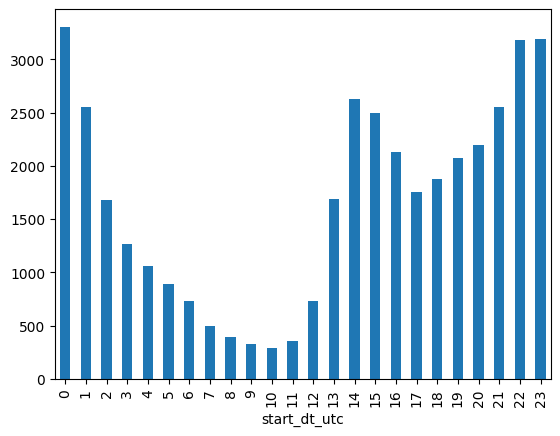

In [54]:
%pip install matplotlib
traffic["start_dt_utc"].dt.hour.value_counts().sort_index().plot(kind="bar")

In [56]:
traffic["start_dt_utc"] = (traffic["start_dt_utc"]
                       .dt.tz_localize("UTC")
                       .dt.tz_convert("America/Edmonton")
                       .dt.tz_localize(None))

In [58]:
traffic["date"] = traffic["start_dt_utc"].dt.date
traffic["hour"] = traffic["start_dt_utc"].dt.hour
traffic[["start_dt_utc", "date", "hour"]].head()

,start_dt_utc,date,hour
163,2023-03-21 12:02:00,2023-03-21,12
241,2026-09-30 18:26:19,2026-09-30,18
242,2026-09-30 20:32:06,2026-09-30,20
243,2026-09-30 21:48:19,2026-09-30,21
244,2026-10-01 00:10:22,2026-10-01,0


In [59]:
print(traffic["quadrant"].value_counts(dropna=False))

quadrant
SE     9963
NE     8566
NaN    8061
NW     7132
SW     6148
Name: count, dtype: int64


In [61]:
traffic = traffic.dropna(subset=["start_dt_utc"])
print(traffic.shape)
traffic.groupby("date").size().describe()

(39870, 9)


count    2027.000000
mean       19.669462
std        10.683422
min         1.000000
25%        12.500000
50%        18.000000
75%        25.000000
max       110.000000
dtype: float64

In [62]:
import pandas as pd

traffic = pd.read_csv("../data/raw/traffic_incidents.csv")

# keep only the columns we need
traffic = traffic[["id", "incident_info", "description",
                   "start_dt_utc", "quadrant", "latitude", "longitude"]].copy()

# drop duplicate incidents
traffic = traffic.drop_duplicates(subset="id")

# parse as UTC, convert to Calgary time, then drop the timezone label
traffic["start_dt"] = (
    pd.to_datetime(traffic["start_dt_utc"], errors="coerce", utc=True)
      .dt.tz_convert("America/Edmonton")
      .dt.tz_localize(None)
)
traffic = traffic.drop(columns="start_dt_utc")
traffic = traffic.dropna(subset=["start_dt"])

# keep winter season only (drop May–September)
traffic = traffic[~traffic["start_dt"].dt.month.isin([5, 6, 7, 8, 9])]

# date and hour in Calgary time
traffic["date"] = traffic["start_dt"].dt.date
traffic["hour"] = traffic["start_dt"].dt.hour

# clean up quadrants
traffic["quadrant"] = traffic["quadrant"].str.strip().str.upper()
traffic = traffic[traffic["quadrant"].isin(["NE", "NW", "SE", "SW"])]

print(traffic.shape)
traffic.groupby("date").size().describe()

(31808, 9)


count    1541.000000
mean       20.641142
std        10.927582
min         1.000000
25%        13.000000
50%        19.000000
75%        26.000000
max       110.000000
dtype: float64